# Cost-sensitive validation analysis

All costs are hypothetical units with orientation **C_FN:C_FP**. Class 1 is serious delinquency within two years, not legal default or realized loss. Thresholds minimize empirical validation cost, using the same development partition used for calibration selection. These costs are development results, not independent generalization estimates. No held-out test evaluation occurs.

A prediction is positive when p >= threshold. Exact cost ties choose the highest candidate threshold (fewer positive decisions). The all-negative reference uses a threshold just above one; preserve its full precision. Curve exports are sampled for display, but optimization considers every distinct score boundary.

## Inputs and reproducibility
Read-only notebook: consumes a saved Member 5 run, does not train models or overwrite upstream outputs. To generate a new run use `.\.venv\Scripts\python.exe -m scripts.run_cost_analysis` from the repository root.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'results/tables/05_cost_analysis'
if not (RUN / 'provenance.json').is_file():
    raise FileNotFoundError('Run python -m scripts.run_cost_analysis first.')
meta = json.loads((RUN / 'provenance.json').read_text())
assert meta['test_evaluated'] is False
print('Run:', RUN.name)
print(meta['interpretation'])
comparison = pd.read_csv(RUN / 'cost_comparison.csv')
selected = pd.read_csv(RUN / 'selected_thresholds.csv')
FIGURES = Path(meta['figures'])


Run: 05_cost_analysis
Validation-selected development results, not independent generalization or actual monetary losses


In [2]:
display(selected[['model_name','cost_ratio','threshold','tn','fp','fn','tp','total_cost','cost_per_observation']])

,model_name,cost_ratio,threshold,tn,fp,fn,tp,total_cost,cost_per_observation
0,logistic_tuned,1:1,0.892531,20886,110,1342,162,1452.0,0.064533
1,logistic_tuned,3:1,0.671058,20191,805,948,556,3649.0,0.162178
2,logistic_tuned,5:1,0.623513,19780,1216,825,679,5341.0,0.237378
3,logistic_tuned,10:1,0.575649,19155,1841,721,783,9051.0,0.402267
4,logistic_tuned__isotonic,1:1,0.541008,20880,116,1336,168,1452.0,0.064533
5,logistic_tuned__isotonic,3:1,0.222451,20190,806,947,557,3647.0,0.162089
6,logistic_tuned__isotonic,5:1,0.175847,19780,1216,828,676,5356.0,0.238044
7,logistic_tuned__isotonic,10:1,0.108924,19044,1952,711,793,9062.0,0.402756
8,random_forest_tuned,1:1,0.457095,20792,204,1195,309,1399.0,0.062178
9,random_forest_tuned,3:1,0.256561,20176,820,821,683,3283.0,0.145911


## Reference decisions
Compare optimized decisions with fixed 0.5, all-positive and all-negative decisions on identical validation rows.

In [3]:
display(comparison.pivot_table(index=['model_name','cost_ratio'], columns='decision', values='total_cost'))

decision                                     all_negative  all_positive  \
model_name                       cost_ratio                               
logistic_tuned                   10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   
logistic_tuned__isotonic         10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   
random_forest_tuned              10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   
random_forest_tuned__isotonic    10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   
xgboost_standard_tuned           10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   
xgboost_standard_tuned__isotonic 10:1             15040.0       20996.0   
                                 1:1               1504.0       20996.0   
                                 3:1               4512.0       20996.0   
                                 5:1               7520.0       20996.0   

decision                                     fixed_0.5  validation_optimum  
model_name                       cost_ratio                                 
logistic_tuned                   10:1           9497.0              9051.0  
                                 1:1            5006.0              1452.0  
                                 3:1            6004.0              3649.0  
                                 5:1            7002.0              5341.0  
logistic_tuned__isotonic         10:1          13094.0              9062.0  
                                 1:1            1457.0              1452.0  
                                 3:1            4043.0              3647.0  
                                 5:1            6629.0              5356.0  
random_forest_tuned              10:1          12910.0              7306.0  
                                 1:1            1435.0              1399.0  
                                 3:1            3985.0              3283.0  
                                 5:1            6535.0              4657.0  
random_forest_tuned__isotonic    10:1          12740.0              7291.0  
                                 1:1            1418.0              1399.0  
                                 3:1            3934.0              3279.0  
                                 5:1            6450.0              4655.0  
xgboost_standard_tuned           10:1          12490.0              7275.0  
                                 1:1            1420.0              1396.0  
                                 3:1            3880.0              3268.0  
                                 5:1            6340.0              4635.0  
xgboost_standard_tuned__isotonic 10:1          12512.0              7296.0  
                                 1:1            1424.0              1402.0  
                                 3:1            3888.0              3271.0  
                                 5:1            6352.0              4621.0

## Calibration comparison
Negative isotonic-minus-uncalibrated cost favors calibration after each candidate separately selects its validation threshold.

In [4]:
display(pd.read_csv(RUN / 'calibration_cost_comparison.csv'))

,base_model,c_fn,c_fp,isotonic,uncalibrated,isotonic_minus_uncalibrated_cost
0,logistic_tuned,1,1,1452.0,1452.0,0.0
1,logistic_tuned,3,1,3647.0,3649.0,-2.0
2,logistic_tuned,5,1,5356.0,5341.0,15.0
3,logistic_tuned,10,1,9062.0,9051.0,11.0
4,random_forest_tuned,1,1,1399.0,1399.0,0.0
5,random_forest_tuned,3,1,3279.0,3283.0,-4.0
6,random_forest_tuned,5,1,4655.0,4657.0,-2.0
7,random_forest_tuned,10,1,7291.0,7306.0,-15.0
8,xgboost_standard_tuned,1,1,1402.0,1396.0,6.0
9,xgboost_standard_tuned,3,1,3271.0,3268.0,3.0


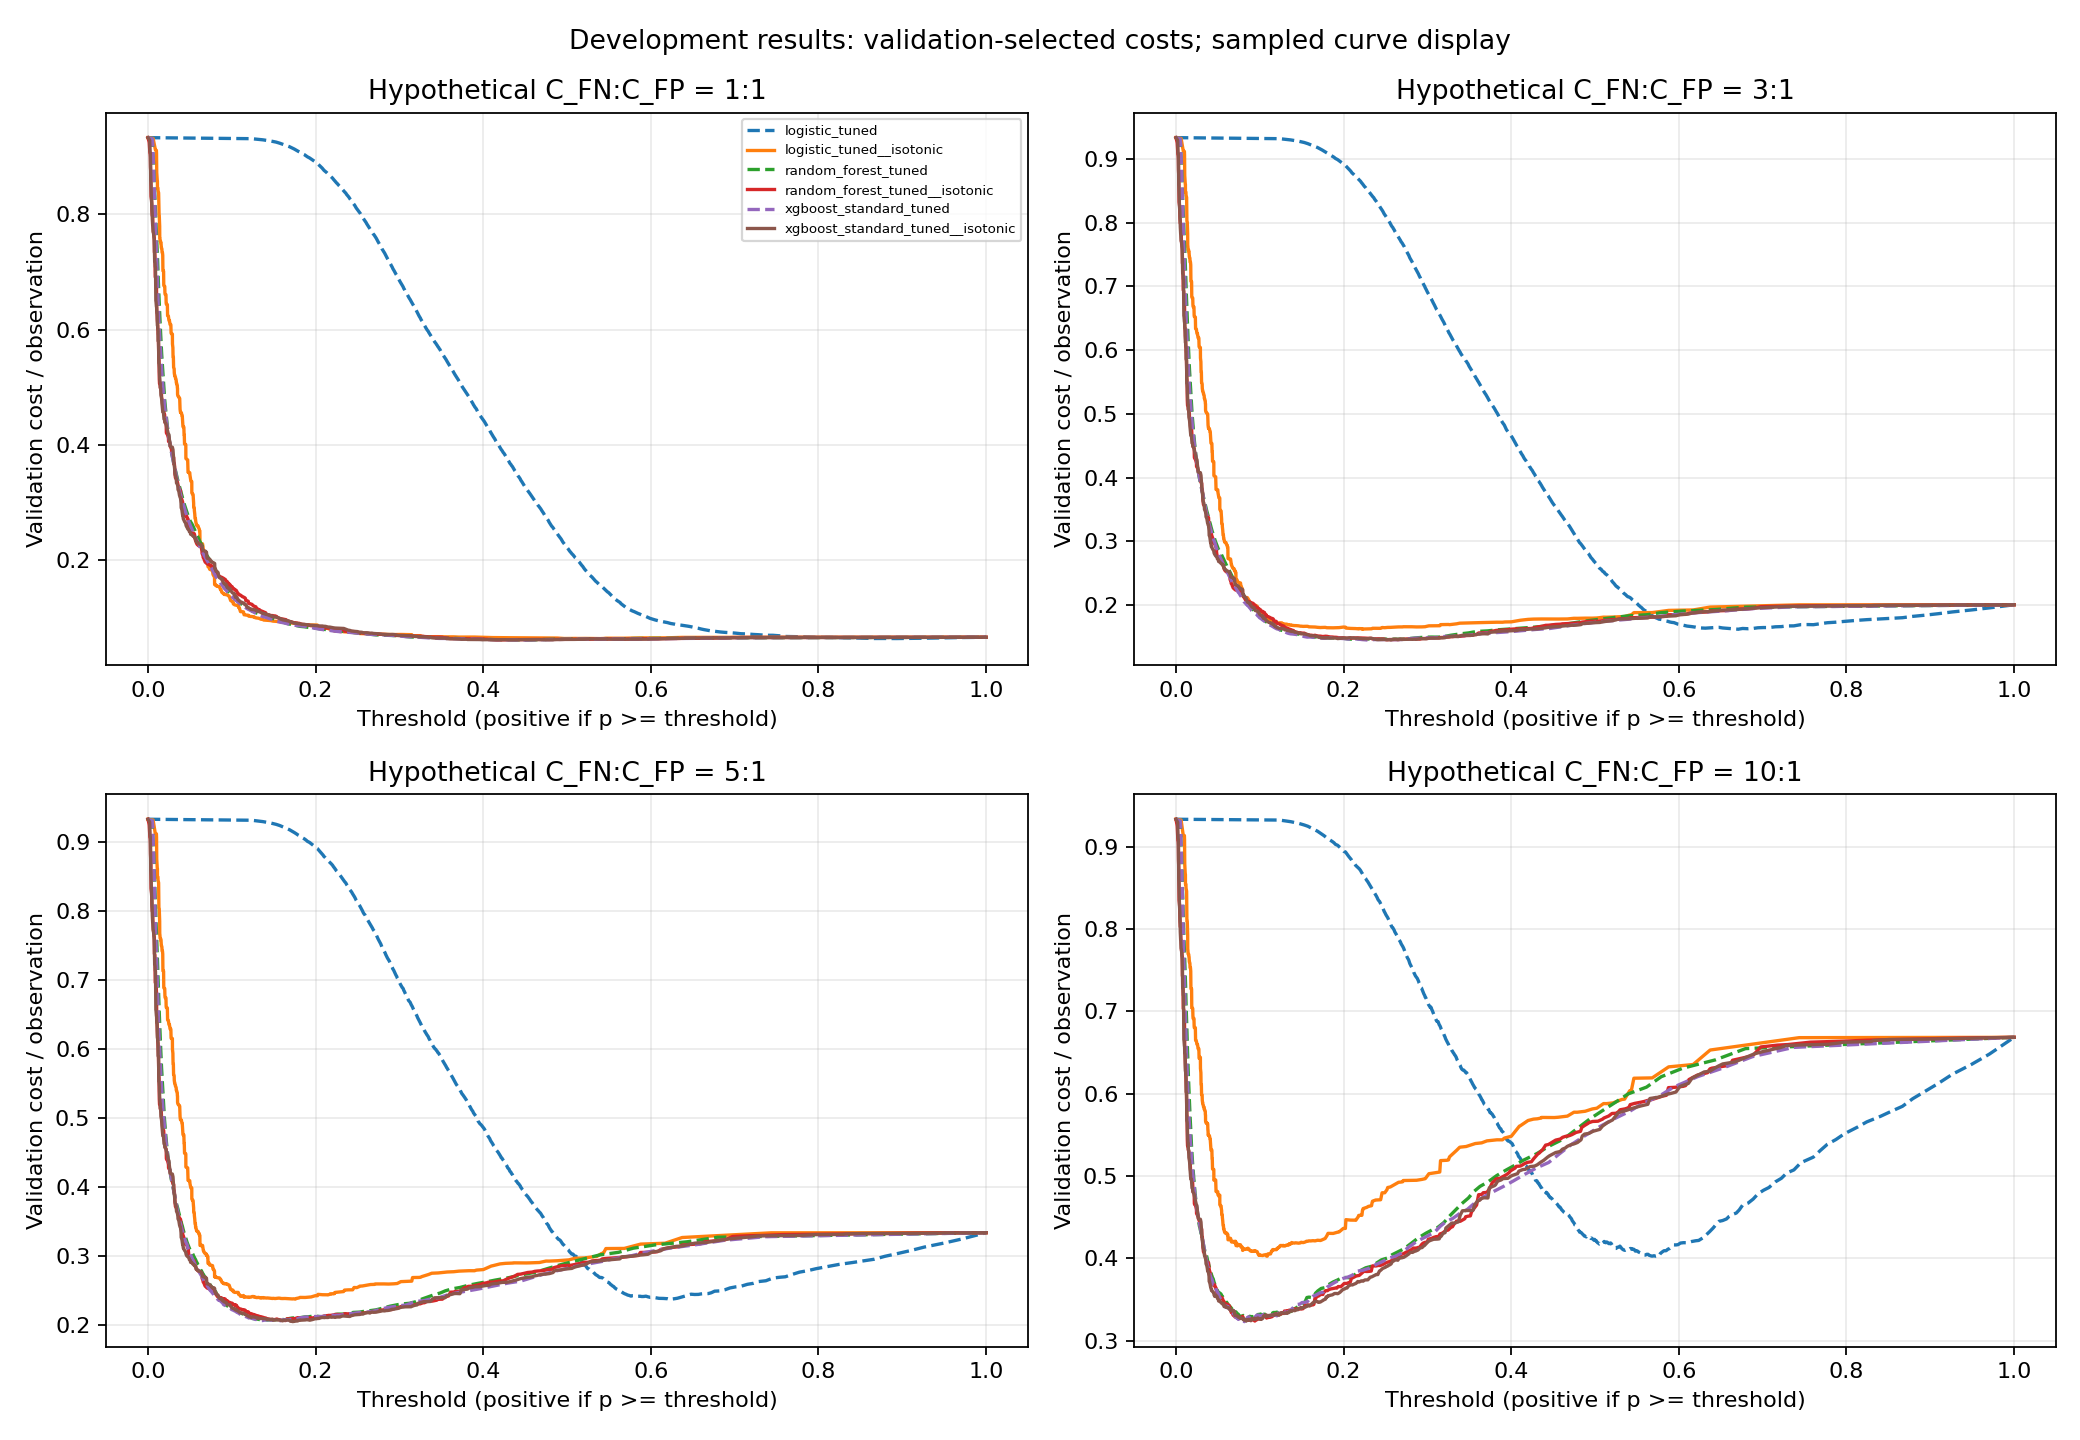

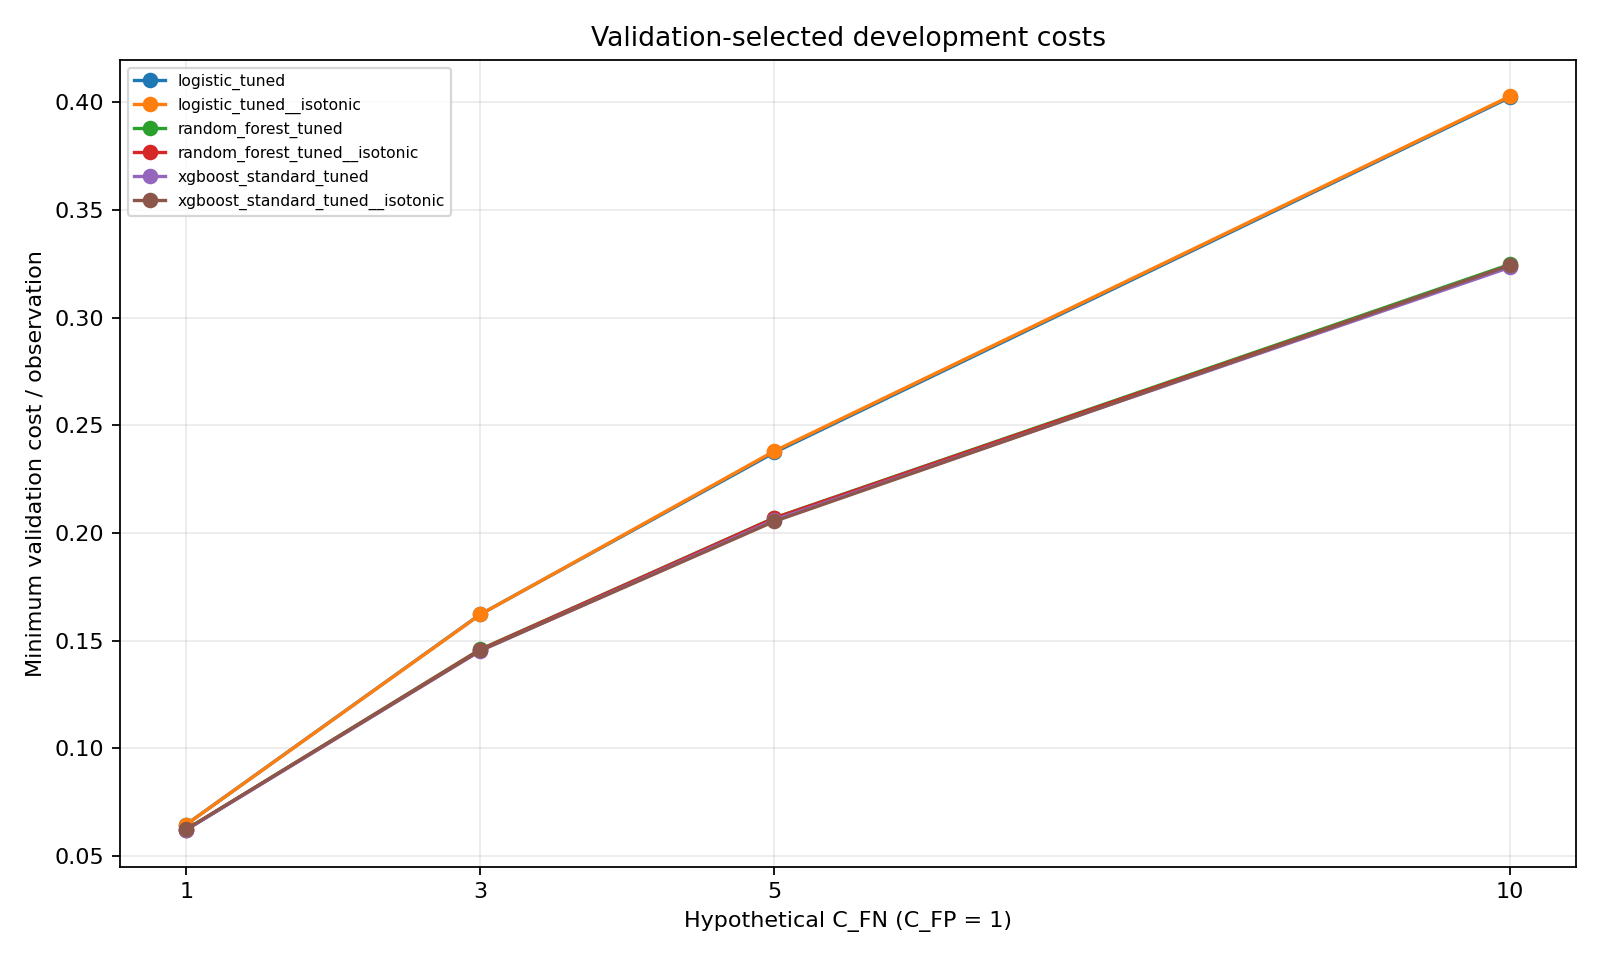

In [5]:
display(Image(filename=str(FIGURES / 'threshold_cost_sensitivity.png')))
display(Image(filename=str(FIGURES / 'cost_ratio_sensitivity.png')))

## Provenance and limitations
Duplicate training/validation records remain in the approved split. Calibration and threshold selection reuse validation. Cost ratios are assumptions, with no claim about bank profit. Upstream parallel XGBoost execution remains unresolved; current artifacts were validated after a successful single-worker run.

In [6]:
display(pd.DataFrame(meta['inputs']).T)
print('Selection:', meta['selection'])
print('Test evaluated:', meta['test_evaluated'])

,path,sha256,sha256_at_generation
logistic_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,d9b42a860fb9eebe30a0cd4fcb941cdbcf078bdcf0a47f...,NaN
logistic_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,ff3c08a35852edfa8d5d96fa386dd3bd06f850be5c9d2d...,NaN
random_forest_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,3afed82e60186962ce663271825710f6a19d44bb4a1d91...,NaN
random_forest_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,0659cda1a10e3588adc454741b98a52a7a443c16bf21e0...,NaN
xgboost_standard_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,57b04a2bd603eb2ba80c958002f6b73b0127af286afecd...,NaN
xgboost_standard_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,a08c131338ee85f37b2493d4d76315f0c2397557df9fe3...,NaN
split_manifest,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,31c2813385ba66e836f41233abeeafca1441c9d782afe2...,NaN
member4_configuration,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,e110c1a304a956e0deafd58fac60fbc66effe23f0c30bf...,aab454b49f34f08f9c0397005261f6a784a9500da40973...
cost_source,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,2b2aaaf012478e18a0128f7d8394230aa79d2d8ccb0b3c...,NaN
runner_source,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,7761405fc200a1ca1b40a8c89997fda523c5345751b167...,3b0720b5bea0a8497c0eead3e531f0f7b6b256d52fca59...


Selection: minimum empirical validation cost; exact ties choose highest threshold
Test evaluated: False
